# ImageNetV2 classification with ResNet-50

> **Updated notebook:** Training is user-controlled. In the first code cell, set `RUN_TRAINING = True`. Set `FORCE_RETRAIN = True` only when you intentionally want to start training again from the pretrained base checkpoint.

This notebook downloads ImageNetV2 locally, evaluates a pinned ImageNet-pretrained ResNet-50, and saves reusable model, manifest, prediction, metric, and optional fine-tuning artifacts. After the first successful run, unchanged work is loaded from disk.

**Recommended use:** leave `RUN_OPTIONAL_FINETUNING = False`. ImageNetV2 is a test set intended to measure distribution-shift robustness, not a training set. Optional fine-tuning is included for experimentation and uses a deterministic per-class split; its full-dataset accuracy is then not a clean benchmark.

Sources: [official ImageNetV2 repository](https://github.com/modestyachts/ImageNetV2), [official PyTorch loader repository](https://github.com/modestyachts/ImageNetV2_pytorch), and [TorchVision ResNet-50 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html).

## 1. Configuration

Edit this cell to change behavior. The remaining cells derive their settings from these values.

In [13]:
from pathlib import Path
import os

# ---------- Paths ----------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

# ---------- Dataset ----------
DATASET_VARIANT = "matched-frequency"  # matched-frequency | threshold-0.7 | top-images
DATASET_SOURCES = {
    "matched-frequency": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz",
        "archive": "imagenetv2-matched-frequency.tar.gz",
        "folder": "imagenetv2-matched-frequency-format-val",
    },
    "threshold-0.7": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-threshold0.7.tar.gz",
        "archive": "imagenetv2-threshold0.7.tar.gz",
        "folder": "imagenetv2-threshold0.7-format-val",
    },
    "top-images": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-top-images.tar.gz",
        "archive": "imagenetv2-top-images.tar.gz",
        "folder": "imagenetv2-top-images-format-val",
    },
}
AUTO_DOWNLOAD_DATASET = True
DELETE_ARCHIVE_AFTER_EXTRACTION = False
DOWNLOAD_CHUNK_MB = 8
DOWNLOAD_RETRIES = 3
EXPECTED_IMAGES = 10_000
EXPECTED_CLASSES = 1_000
IMAGE_EXTENSIONS = (".jpeg", ".jpg", ".png", ".webp")

# ---------- Environment ----------
INSTALL_MISSING_PACKAGES = True
PACKAGE_IMPORTS = {
    "torch": "torch", "torchvision": "torchvision", "requests": "requests",
    "tqdm": "tqdm", "pandas": "pandas", "matplotlib": "matplotlib",
    "Pillow": "PIL",
}
RANDOM_SEED = 42
DEVICE_PREFERENCE = "auto"  # auto | cuda | mps | cpu
NUM_WORKERS = 0  # safest for Jupyter and Python 3.14; increase only if multiprocessing works
DATALOADER_FALLBACK_TO_SINGLE_PROCESS = True
PIN_MEMORY = True

# ---------- Model and inference ----------
MODEL_WEIGHTS = "IMAGENET1K_V2"  # pinned; avoids DEFAULT changing later
BATCH_SIZE = 64
USE_MIXED_PRECISION = True
TOP_K = 5
FORCE_RECOMPUTE_PREDICTIONS = False
MAX_EVAL_IMAGES = None  # None = all 10,000; use a positive integer for a quick test

# ---------- Optional fine-tuning ----------
RUN_TRAINING = False
RUN_OPTIONAL_FINETUNING = RUN_TRAINING  # compatibility alias; change RUN_TRAINING only
FORCE_RETRAIN = True
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
EPOCHS = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
UNFREEZE_LAYER4 = True
EARLY_STOPPING_PATIENCE = 2
IMAGE_SIZE = 224
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)

# ---------- Display and custom-image inference ----------
NUM_EXAMPLES_TO_SHOW = 12
CUSTOM_IMAGE_PATH = None  # e.g. PROJECT_DIR / "my_photo.jpg"

assert DATASET_VARIANT in DATASET_SOURCES, f"Unknown DATASET_VARIANT: {DATASET_VARIANT}"
assert BATCH_SIZE > 0 and 1 <= TOP_K <= EXPECTED_CLASSES and NUM_EXAMPLES_TO_SHOW > 0
assert 0 < TRAIN_FRACTION < 1 and 0 <= VALIDATION_FRACTION < 1
assert TRAIN_FRACTION + VALIDATION_FRACTION < 1
if RUN_OPTIONAL_FINETUNING:
    images_per_class = EXPECTED_IMAGES // EXPECTED_CLASSES
    assert int(images_per_class * VALIDATION_FRACTION) >= 1, "Validation split needs at least one image per class."
    assert images_per_class - int(images_per_class * TRAIN_FRACTION) - int(images_per_class * VALIDATION_FRACTION) >= 1, "Test split needs at least one image per class."
source = DATASET_SOURCES[DATASET_VARIANT]
DATASET_ROOT = DATA_DIR / source["folder"]
ARCHIVE_PATH = DATA_DIR / source["archive"]
MANIFEST_PATH = ARTIFACT_DIR / f"imagenetv2_{DATASET_VARIANT}_manifest.csv"
BASE_MODEL_PATH = ARTIFACT_DIR / f"resnet50_{MODEL_WEIGHTS.lower()}_base.pt"
FINETUNED_MODEL_PATH = ARTIFACT_DIR / f"resnet50_{MODEL_WEIGHTS.lower()}_{DATASET_VARIANT}_finetuned.pt"
ACTIVE_MODEL_PATH = FINETUNED_MODEL_PATH if RUN_OPTIONAL_FINETUNING else BASE_MODEL_PATH
PREDICTIONS_PATH = ARTIFACT_DIR / f"predictions_{DATASET_VARIANT}_{ACTIVE_MODEL_PATH.stem}.csv"
METRICS_PATH = ARTIFACT_DIR / f"metrics_{DATASET_VARIANT}_{ACTIVE_MODEL_PATH.stem}.json"
CACHE_METADATA_PATH = ARTIFACT_DIR / f"cache_{DATASET_VARIANT}_{ACTIVE_MODEL_PATH.stem}.json"
CLASS_NAMES_PATH = ARTIFACT_DIR / "imagenet1k_class_names.json"

print(f"Dataset: {DATASET_VARIANT} -> {DATASET_ROOT}")
print(f"Active model artifact: {ACTIVE_MODEL_PATH}")

Dataset: matched-frequency -> /home/abbi/tamug_hdc_uav_v2/data/imagenetv2-matched-frequency-format-val
Active model artifact: /home/abbi/tamug_hdc_uav_v2/artifacts/resnet50_imagenet1k_v2_base.pt


## 2. Install/import dependencies and initialize the session

In [14]:
import importlib.util
import subprocess
import sys

missing_packages = [pkg for pkg, module in PACKAGE_IMPORTS.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    if not INSTALL_MISSING_PACKAGES:
        raise ModuleNotFoundError(f"Missing packages: {missing_packages}. Set INSTALL_MISSING_PACKAGES=True.")
    print("Installing missing packages:", ", ".join(missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
else:
    print("All required packages are installed.")

All required packages are installed.


In [15]:
import contextlib
import hashlib
import json
import random
import shutil
import tarfile
from collections import defaultdict
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50
from tqdm.auto import tqdm

DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

def select_device(preference):
    if preference == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    device = torch.device(preference)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable. Use DEVICE_PREFERENCE='auto' or 'cpu'.")
    if device.type == "mps" and not (hasattr(torch.backends, "mps") and torch.backends.mps.is_available()):
        raise RuntimeError("MPS was requested but is unavailable.")
    return device

DEVICE = select_device(DEVICE_PREFERENCE)
AMP_ENABLED = USE_MIXED_PRECISION and DEVICE.type == "cuda"
def loader_options(force_single_process=False):
    workers = 0 if force_single_process else NUM_WORKERS
    return {
        "num_workers": workers,
        "pin_memory": PIN_MEMORY and DEVICE.type == "cuda",
        "persistent_workers": workers > 0,
    }

def make_data_loader(dataset, *, shuffle=False, force_single_process=False):
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        **loader_options(force_single_process=force_single_process),
    )

LOADER_KWARGS = loader_options()
print(f"PyTorch {torch.__version__} | device={DEVICE} | AMP={AMP_ENABLED} | workers={NUM_WORKERS}")

PyTorch 2.14.1+cu130 | device=cuda | AMP=True | workers=0


## 3. Download and safely extract ImageNetV2

The archive is roughly 1.25 GB. Partial downloads resume from a `.part` file. Existing valid extracted data is reused. The source may serve an uncompressed tar even though its filename ends in `.tar.gz`; extraction detects the format from the file content.

In [16]:
def image_files(root):
    if not root.exists():
        return []
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def dataset_is_complete(root):
    return root.is_dir() and len(image_files(root)) == EXPECTED_IMAGES

def archive_is_readable(path):
    if not path.is_file() or path.stat().st_size == 0:
        return False
    try:
        # r:* detects gzip, bzip2, xz, or an uncompressed tar from its content.
        with tarfile.open(path, "r:*") as archive:
            return archive.next() is not None
    except (tarfile.TarError, OSError):
        return False

def download_with_resume(url, destination):
    part_path = destination.with_suffix(destination.suffix + ".part")
    existing = part_path.stat().st_size if part_path.exists() else 0
    headers = {"Range": f"bytes={existing}-"} if existing else {}
    with requests.get(url, stream=True, headers=headers, timeout=(30, 120), allow_redirects=True) as response:
        response.raise_for_status()
        if existing and response.status_code != 206:
            print("Server did not honor resume; restarting the download.")
            existing = 0
        mode = "ab" if existing else "wb"
        content_length = int(response.headers.get("content-length", 0))
        total = existing + content_length if content_length else None
        with open(part_path, mode) as handle, tqdm(
            total=total, initial=existing, unit="B", unit_scale=True, desc=destination.name
        ) as progress:
            for chunk in response.iter_content(chunk_size=DOWNLOAD_CHUNK_MB * 1024 * 1024):
                if chunk:
                    handle.write(chunk)
                    progress.update(len(chunk))
    part_path.replace(destination)
    if not archive_is_readable(destination):
        raise RuntimeError(
            f"Downloaded file is not a readable tar archive: {destination}. "
            "The server may have returned an error page instead of the dataset."
        )
    return destination

def safe_extract_tar(archive_path, destination):
    destination_resolved = destination.resolve()
    # Use r:* because the official host can return a plain tar with a .tar.gz name.
    with tarfile.open(archive_path, "r:*") as archive:
        for member in archive.getmembers():
            target = (destination / member.name).resolve()
            if destination_resolved != target and destination_resolved not in target.parents:
                raise RuntimeError(f"Unsafe archive path: {member.name}")
            if member.issym() or member.islnk():
                raise RuntimeError(f"Archive links are not allowed: {member.name}")
        try:
            archive.extractall(destination, filter="data")
        except TypeError:  # Python versions before the filter argument
            archive.extractall(destination)

if dataset_is_complete(DATASET_ROOT):
    print(f"Using existing dataset: {DATASET_ROOT}")
else:
    if not AUTO_DOWNLOAD_DATASET:
        raise FileNotFoundError(f"Dataset not found at {DATASET_ROOT}; enable AUTO_DOWNLOAD_DATASET.")
    if ARCHIVE_PATH.exists() and not archive_is_readable(ARCHIVE_PATH):
        invalid_path = ARCHIVE_PATH.with_name(ARCHIVE_PATH.name + ".invalid")
        if invalid_path.exists():
            invalid_path = ARCHIVE_PATH.with_name(ARCHIVE_PATH.name + f".{int(datetime.now().timestamp())}.invalid")
        ARCHIVE_PATH.replace(invalid_path)
        print(f"Moved an invalid cached download to: {invalid_path}")
    if not ARCHIVE_PATH.exists():
        last_error = None
        for attempt in range(1, DOWNLOAD_RETRIES + 1):
            try:
                print(f"Downloading {source['url']} (attempt {attempt}/{DOWNLOAD_RETRIES})")
                download_with_resume(source["url"], ARCHIVE_PATH)
                break
            except (requests.RequestException, OSError, RuntimeError) as error:
                last_error = error
                print(f"Download attempt failed: {error}")
                if ARCHIVE_PATH.exists() and not archive_is_readable(ARCHIVE_PATH):
                    ARCHIVE_PATH.unlink()
                part_path = ARCHIVE_PATH.with_suffix(ARCHIVE_PATH.suffix + ".part")
                if part_path.exists() and attempt == DOWNLOAD_RETRIES:
                    part_path.unlink()
        if not ARCHIVE_PATH.exists():
            raise RuntimeError(f"Dataset download failed after {DOWNLOAD_RETRIES} attempts.") from last_error
    else:
        print(f"Using existing readable archive: {ARCHIVE_PATH}")
    print("Extracting archive...")
    safe_extract_tar(ARCHIVE_PATH, DATA_DIR)
    if not dataset_is_complete(DATASET_ROOT):
        count = len(image_files(DATASET_ROOT))
        raise RuntimeError(f"Expected {EXPECTED_IMAGES:,} images at {DATASET_ROOT}, found {count:,}.")
    if DELETE_ARCHIVE_AFTER_EXTRACTION:
        ARCHIVE_PATH.unlink()
        print(f"Deleted archive: {ARCHIVE_PATH}")

print(f"Dataset ready: {len(image_files(DATASET_ROOT)):,} images")

Using existing dataset: /home/abbi/tamug_hdc_uav_v2/data/imagenetv2-matched-frequency-format-val
Dataset ready: 10,000 images


## 4. Build and validate a numeric-label dataset

Labels come from each image's numeric parent folder. This avoids lexicographic folder ordering (`0, 1, 10, ...`) from corrupting the ImageNet class indices.

In [17]:
WEIGHTS = getattr(ResNet50_Weights, MODEL_WEIGHTS)
CLASS_NAMES = list(WEIGHTS.meta["categories"])
if len(CLASS_NAMES) != EXPECTED_CLASSES:
    raise RuntimeError(f"Expected {EXPECTED_CLASSES} weight categories, found {len(CLASS_NAMES)}.")
CLASS_NAMES_PATH.write_text(json.dumps(CLASS_NAMES, indent=2))

class ImageNetV2Local(Dataset):
    def __init__(self, root, transform=None, samples=None):
        self.root = Path(root)
        self.transform = transform
        if samples is None:
            paths = image_files(self.root)
            samples = [(path, int(path.parent.name)) for path in paths]
        self.samples = sorted(samples, key=lambda item: (item[1], item[0].name))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, target = self.samples[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, target, str(path)

all_paths = image_files(DATASET_ROOT)
samples = [(path, int(path.parent.name)) for path in all_paths]
labels = [label for _, label in samples]
observed_classes = sorted(set(labels))
expected_class_ids = list(range(EXPECTED_CLASSES))
if len(samples) != EXPECTED_IMAGES:
    raise RuntimeError(f"Expected {EXPECTED_IMAGES:,} images, found {len(samples):,}.")
if observed_classes != expected_class_ids:
    missing = sorted(set(expected_class_ids) - set(observed_classes))
    extra = sorted(set(observed_classes) - set(expected_class_ids))
    raise RuntimeError(f"Class folders are invalid. Missing={missing[:10]}, extra={extra[:10]}")
counts = pd.Series(labels).value_counts().sort_index()
if not (counts == EXPECTED_IMAGES // EXPECTED_CLASSES).all():
    raise RuntimeError("Expected exactly 10 images per ImageNetV2 class.")

manifest = pd.DataFrame({
    "relative_path": [str(path.relative_to(DATASET_ROOT)) for path, _ in samples],
    "target_idx": labels,
    "target_name": [CLASS_NAMES[label] for label in labels],
    "size_bytes": [path.stat().st_size for path, _ in samples],
}).sort_values(["target_idx", "relative_path"]).reset_index(drop=True)
manifest.to_csv(MANIFEST_PATH, index=False)
print(f"Validated {len(manifest):,} images across {len(counts):,} classes.")
display(manifest.head())

Validated 10,000 images across 1,000 classes.


,relative_path,target_idx,target_name,size_bytes
0,0/58fbc3e79ef15162b7726de04e98c90bb91a3055.jpeg,0,tench,119704
1,0/64f661b97cfd6db73bd6c30325597cf7c7b322d5.jpeg,0,tench,51592
2,0/66123ec1b806abff544bb89e11653ef5185af4be.jpeg,0,tench,188804
3,0/7e4a8987a9a330189cc38c4098b1c57ac301713f.jpeg,0,tench,88496
4,0/8e1374a4e20d7af22665b7749158b7eb9fa3826e.jpeg,0,tench,202665


## 5. Create deterministic transforms and optional train/validation/test splits

In [18]:
EVAL_TRANSFORM = WEIGHTS.transforms()
TRAIN_TRANSFORM = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

def stratified_indices(dataset_samples, train_fraction, validation_fraction, seed):
    grouped = defaultdict(list)
    for index, (_, label) in enumerate(dataset_samples):
        grouped[label].append(index)
    rng = random.Random(seed)
    train_indices, validation_indices, test_indices = [], [], []
    for label in sorted(grouped):
        indices = grouped[label][:]
        rng.shuffle(indices)
        n_train = int(len(indices) * train_fraction)
        n_validation = int(len(indices) * validation_fraction)
        train_indices.extend(indices[:n_train])
        validation_indices.extend(indices[n_train:n_train + n_validation])
        test_indices.extend(indices[n_train + n_validation:])
    return train_indices, validation_indices, test_indices

train_indices, validation_indices, test_indices = stratified_indices(
    samples, TRAIN_FRACTION, VALIDATION_FRACTION, RANDOM_SEED
)
train_dataset = Subset(ImageNetV2Local(DATASET_ROOT, TRAIN_TRANSFORM, samples), train_indices)
validation_dataset = Subset(ImageNetV2Local(DATASET_ROOT, EVAL_TRANSFORM, samples), validation_indices)
test_dataset = Subset(ImageNetV2Local(DATASET_ROOT, EVAL_TRANSFORM, samples), test_indices)
full_dataset = ImageNetV2Local(DATASET_ROOT, EVAL_TRANSFORM, samples)
if MAX_EVAL_IMAGES is not None:
    if not 0 < MAX_EVAL_IMAGES <= len(full_dataset):
        raise ValueError("MAX_EVAL_IMAGES must be between 1 and the dataset size.")
    eval_dataset = Subset(full_dataset, list(range(MAX_EVAL_IMAGES)))
else:
    eval_dataset = full_dataset

print(f"Optional fine-tuning split: train={len(train_dataset):,}, val={len(validation_dataset):,}, test={len(test_dataset):,}")
print(f"Full evaluation set: {len(eval_dataset):,} images")

Optional fine-tuning split: train=7,000, val=1,000, test=2,000
Full evaluation set: 10,000 images


## 6. Load ResNet-50 and persist its reusable base artifact

On the first run, TorchVision downloads the pinned pretrained weights (about 98 MB) and this cell stores a local checkpoint. Later runs construct the architecture without downloading weights and load the checkpoint.

In [19]:
def load_checkpoint(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)

def save_checkpoint(path, model, artifact_type, history=None, extra=None):
    payload = {
        "model_state_dict": model.state_dict(),
        "architecture": "resnet50",
        "weights": MODEL_WEIGHTS,
        "artifact_type": artifact_type,
        "dataset_variant": DATASET_VARIANT,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "history": history or [],
        "extra": extra or {},
    }
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def model_from_checkpoint(path):
    checkpoint = load_checkpoint(path)
    loaded_model = resnet50(weights=None)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    return loaded_model, checkpoint

if BASE_MODEL_PATH.exists():
    model, base_checkpoint = model_from_checkpoint(BASE_MODEL_PATH)
    print(f"Loaded local base model: {BASE_MODEL_PATH}")
else:
    print(f"Creating ResNet-50 with {MODEL_WEIGHTS} weights...")
    model = resnet50(weights=WEIGHTS)
    save_checkpoint(BASE_MODEL_PATH, model, artifact_type="pretrained_base")
    base_checkpoint = load_checkpoint(BASE_MODEL_PATH)
    print(f"Saved reusable base model: {BASE_MODEL_PATH}")

model = model.to(DEVICE)
model.eval()
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

Loaded local base model: /home/abbi/tamug_hdc_uav_v2/artifacts/resnet50_imagenet1k_v2_base.pt
Parameters: 25,557,032


## 7. Optional fine-tuning with checkpoint reuse

This entire section is skipped by default. If enabled, an existing fine-tuned checkpoint is loaded unless `FORCE_RETRAIN = True`. The best validation checkpoint is saved atomically.

In [20]:
def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()

def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

def evaluate_accuracy(current_model, loader):
    current_model.eval()
    correct, total, loss_total = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss()
    with torch.inference_mode():
        for images, targets, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = current_model(images)
                loss = criterion(logits, targets)
            loss_total += loss.item() * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)
    return {"loss": loss_total / total, "accuracy": correct / total}

def configure_trainable_parameters(current_model):
    for parameter in current_model.parameters():
        parameter.requires_grad = False
    for parameter in current_model.fc.parameters():
        parameter.requires_grad = True
    if UNFREEZE_LAYER4:
        for parameter in current_model.layer4.parameters():
            parameter.requires_grad = True

def freeze_batch_norm_statistics(current_model):
    for module in current_model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

training_history = []
if RUN_OPTIONAL_FINETUNING:
    if FINETUNED_MODEL_PATH.exists() and not FORCE_RETRAIN:
        model, fine_checkpoint = model_from_checkpoint(FINETUNED_MODEL_PATH)
        model = model.to(DEVICE).eval()
        training_history = fine_checkpoint.get("history", [])
        print(f"Loaded fine-tuned artifact; training skipped: {FINETUNED_MODEL_PATH}")
    else:
        if FORCE_RETRAIN:
            model, _ = model_from_checkpoint(BASE_MODEL_PATH)
            model = model.to(DEVICE)
        configure_trainable_parameters(model)
        optimizer = torch.optim.AdamW(
            (parameter for parameter in model.parameters() if parameter.requires_grad),
            lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, EPOCHS))
        criterion = nn.CrossEntropyLoss()
        scaler = make_grad_scaler()
        train_loader = make_data_loader(train_dataset, shuffle=True)
        validation_loader = make_data_loader(validation_dataset, shuffle=False)
        best_accuracy, epochs_without_improvement = -1.0, 0

        for epoch in range(1, EPOCHS + 1):
            model.train()
            freeze_batch_norm_statistics(model)
            running_loss, seen = 0.0, 0
            progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
            for images, targets, _ in progress:
                images = images.to(DEVICE, non_blocking=True)
                targets = targets.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with autocast_context():
                    logits = model(images)
                    loss = criterion(logits, targets)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                running_loss += loss.item() * targets.size(0)
                seen += targets.size(0)
                progress.set_postfix(train_loss=f"{running_loss / seen:.4f}")
            validation_metrics = evaluate_accuracy(model, validation_loader)
            epoch_record = {
                "epoch": epoch, "train_loss": running_loss / seen,
                "validation_loss": validation_metrics["loss"],
                "validation_accuracy": validation_metrics["accuracy"],
                "learning_rate": optimizer.param_groups[0]["lr"],
            }
            training_history.append(epoch_record)
            print(epoch_record)
            if validation_metrics["accuracy"] > best_accuracy:
                best_accuracy = validation_metrics["accuracy"]
                epochs_without_improvement = 0
                save_checkpoint(
                    FINETUNED_MODEL_PATH, model, "finetuned", training_history,
                    {"best_validation_accuracy": best_accuracy, "split_seed": RANDOM_SEED},
                )
                print(f"Saved new best checkpoint: {FINETUNED_MODEL_PATH}")
            else:
                epochs_without_improvement += 1
            scheduler.step()
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print("Early stopping triggered.")
                break
        model, fine_checkpoint = model_from_checkpoint(FINETUNED_MODEL_PATH)
        model = model.to(DEVICE).eval()
else:
    print("Fine-tuning disabled; using the original ImageNet-pretrained model.")

Fine-tuning disabled; using the original ImageNet-pretrained model.


## 8. Classify ImageNetV2 and cache predictions/metrics

The prediction cache is reused only when its model hash, manifest hash, evaluation size, and configuration match.

In [21]:
def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

active_model_hash = sha256_file(ACTIVE_MODEL_PATH)
manifest_hash = sha256_file(MANIFEST_PATH)
cache_identity = {
    "dataset_variant": DATASET_VARIANT,
    "dataset_manifest_sha256": manifest_hash,
    "model_artifact_sha256": active_model_hash,
    "model_weights": MODEL_WEIGHTS,
    "evaluation_images": len(eval_dataset),
    "top_k": TOP_K,
}

def cache_is_valid():
    if FORCE_RECOMPUTE_PREDICTIONS:
        return False
    if not (PREDICTIONS_PATH.exists() and METRICS_PATH.exists() and CACHE_METADATA_PATH.exists()):
        return False
    try:
        metadata = json.loads(CACHE_METADATA_PATH.read_text())
        return metadata == cache_identity
    except (json.JSONDecodeError, OSError):
        return False

def collect_predictions(current_model, loader):
    rows = []
    current_model.eval()
    with torch.inference_mode():
        for images, targets, paths in tqdm(loader, desc="Classifying ImageNetV2"):
            images = images.to(DEVICE, non_blocking=True)
            targets_device = targets.to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = current_model(images)
                probabilities = torch.softmax(logits.float(), dim=1)
            top_probabilities, top_indices = probabilities.topk(TOP_K, dim=1)
            top_probabilities = top_probabilities.cpu().numpy()
            top_indices = top_indices.cpu().numpy()
            targets_np = targets_device.cpu().numpy()
            for path, target, indices, probs in zip(paths, targets_np, top_indices, top_probabilities):
                indices_list = [int(value) for value in indices]
                probs_list = [float(value) for value in probs]
                rows.append({
                    "image_path": str(Path(path).relative_to(DATASET_ROOT)),
                    "target_idx": int(target),
                    "target_name": CLASS_NAMES[int(target)],
                    "predicted_idx": indices_list[0],
                    "predicted_name": CLASS_NAMES[indices_list[0]],
                    "confidence": probs_list[0],
                    "correct_top1": indices_list[0] == int(target),
                    "correct_top5": int(target) in indices_list,
                    "top5_indices": json.dumps(indices_list),
                    "top5_names": json.dumps([CLASS_NAMES[index] for index in indices_list]),
                    "top5_probabilities": json.dumps(probs_list),
                })
    return pd.DataFrame(rows)

def is_dataloader_worker_failure(error):
    if isinstance(error, (BrokenPipeError, EOFError)):
        return True
    if isinstance(error, OSError) and getattr(error, "errno", None) in {32, 104}:
        return True
    message = str(error).lower()
    markers = ("dataloader worker", "worker exited unexpectedly", "broken pipe", "forkserver", "pickle")
    return any(marker in message for marker in markers)

def run_inference(current_model, dataset):
    loader = make_data_loader(dataset, shuffle=False)
    try:
        return collect_predictions(current_model, loader)
    except (BrokenPipeError, EOFError, OSError, RuntimeError) as error:
        fallback_enabled = globals().get("DATALOADER_FALLBACK_TO_SINGLE_PROCESS", True)
        if not fallback_enabled or LOADER_KWARGS.get("num_workers", 0) == 0 or not is_dataloader_worker_failure(error):
            raise
        print(f"DataLoader multiprocessing failed ({type(error).__name__}: {error}).")
        print("Restarting inference safely with num_workers=0...")
        single_process_loader = make_data_loader(dataset, shuffle=False, force_single_process=True)
        return collect_predictions(current_model, single_process_loader)

if cache_is_valid():
    predictions = pd.read_csv(PREDICTIONS_PATH)
    metrics = json.loads(METRICS_PATH.read_text())
    print(f"Loaded {len(predictions):,} cached predictions from {PREDICTIONS_PATH}")
else:
    predictions = run_inference(model, eval_dataset)
    metrics = {
        "dataset_variant": DATASET_VARIANT,
        "model_artifact": str(ACTIVE_MODEL_PATH),
        "model_weights": MODEL_WEIGHTS,
        "fine_tuned_on_imagenetv2": RUN_OPTIONAL_FINETUNING,
        "num_images": len(predictions),
        "top1_accuracy": float(predictions["correct_top1"].mean()),
        "top5_accuracy": float(predictions["correct_top5"].mean()),
        "mean_top1_confidence": float(predictions["confidence"].mean()),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": (
            "Full-set accuracy includes images used for optional fine-tuning and is not a clean benchmark."
            if RUN_OPTIONAL_FINETUNING else
            "Evaluation uses the original pretrained model; no ImageNetV2 images were used for training."
        ),
    }
    predictions.to_csv(PREDICTIONS_PATH, index=False)
    METRICS_PATH.write_text(json.dumps(metrics, indent=2))
    CACHE_METADATA_PATH.write_text(json.dumps(cache_identity, indent=2))
    print(f"Saved predictions: {PREDICTIONS_PATH}")

print(json.dumps(metrics, indent=2))

Loaded 10,000 cached predictions from /home/abbi/tamug_hdc_uav_v2/artifacts/predictions_matched-frequency_resnet50_imagenet1k_v2_base.csv
{
  "dataset_variant": "matched-frequency",
  "model_artifact": "/home/abbi/tamug_hdc_uav_v2/artifacts/resnet50_imagenet1k_v2_base.pt",
  "model_weights": "IMAGENET1K_V2",
  "fine_tuned_on_imagenetv2": false,
  "num_images": 10000,
  "top1_accuracy": 0.6991,
  "top5_accuracy": 0.8888,
  "mean_top1_confidence": 0.35214071102961897,
  "created_at_utc": "2026-10-05T03:32:45.203354+00:00",
  "note": "Evaluation uses the original pretrained model; no ImageNetV2 images were used for training."
}


## 9. Inspect results

,image_path,target_idx,target_name,predicted_idx,predicted_name,confidence,correct_top1,correct_top5,top5_indices,top5_names,top5_probabilities
0,0/58fbc3e79ef15162b7726de04e98c90bb91a3055.jpeg,0,tench,0,tench,0.565100,True,True,"[0, 389, 29, 103, 652]","[""tench"", ""barracouta"", ""axolotl"", ""platypus"",...","[0.5650998950004578, 0.0017330676782876253, 0...."
1,0/64f661b97cfd6db73bd6c30325597cf7c7b322d5.jpeg,0,tench,0,tench,0.640992,True,True,"[0, 389, 394, 391, 395]","[""tench"", ""barracouta"", ""sturgeon"", ""coho"", ""g...","[0.640992283821106, 0.08342558145523071, 0.009..."
2,0/66123ec1b806abff544bb89e11653ef5185af4be.jpeg,0,tench,0,tench,0.331134,True,True,"[0, 391, 758, 390, 119]","[""tench"", ""coho"", ""reel"", ""eel"", ""rock crab""]","[0.33113399147987366, 0.003336315043270588, 0...."
3,0/7e4a8987a9a330189cc38c4098b1c57ac301713f.jpeg,0,tench,0,tench,0.560724,True,True,"[0, 389, 103, 29, 715]","[""tench"", ""barracouta"", ""platypus"", ""axolotl"",...","[0.5607239007949829, 0.0017382196383550763, 0...."
4,0/8e1374a4e20d7af22665b7749158b7eb9fa3826e.jpeg,0,tench,0,tench,0.532904,True,True,"[0, 715, 31, 806, 955]","[""tench"", ""pickelhaube"", ""tree frog"", ""sock"", ...","[0.5329040884971619, 0.0014324641088023782, 0...."
5,0/bcf8a5326180b5e9320642f5024096fbc8a5d454.jpeg,0,tench,0,tench,0.561501,True,True,"[0, 669, 389, 715, 941]","[""tench"", ""mosquito net"", ""barracouta"", ""picke...","[0.5615006685256958, 0.001906112884171307, 0.0..."
6,0/c0c1167c3683ef5887a4803ee7c77ef2d1a93276.jpeg,0,tench,0,tench,0.472397,True,True,"[0, 389, 29, 652, 329]","[""tench"", ""barracouta"", ""axolotl"", ""military u...","[0.4723966419696808, 0.004000161308795214, 0.0..."
7,0/cc19eded6ed2e6a5b47b733552b97ba59c27d66d.jpeg,0,tench,0,tench,0.519653,True,True,"[0, 389, 758, 410, 428]","[""tench"", ""barracouta"", ""reel"", ""apiary"", ""bar...","[0.5196526646614075, 0.0019950331188738346, 0...."
8,0/d337d803d2ca57a80e880cb0686ea96e5d4ca8c7.jpeg,0,tench,749,quill,0.026590,False,False,"[749, 954, 998, 666, 738]","[""quill"", ""banana"", ""ear"", ""mortar"", ""pot""]","[0.026589740067720413, 0.025671187788248062, 0..."
9,0/efae46d9adcc5d4578a91a028a259703ebd85ffe.jpeg,0,tench,0,tench,0.477469,True,True,"[0, 828, 556, 709, 489]","[""tench"", ""strainer"", ""fire screen"", ""pencil b...","[0.47746872901916504, 0.00421238923445344, 0.0..."


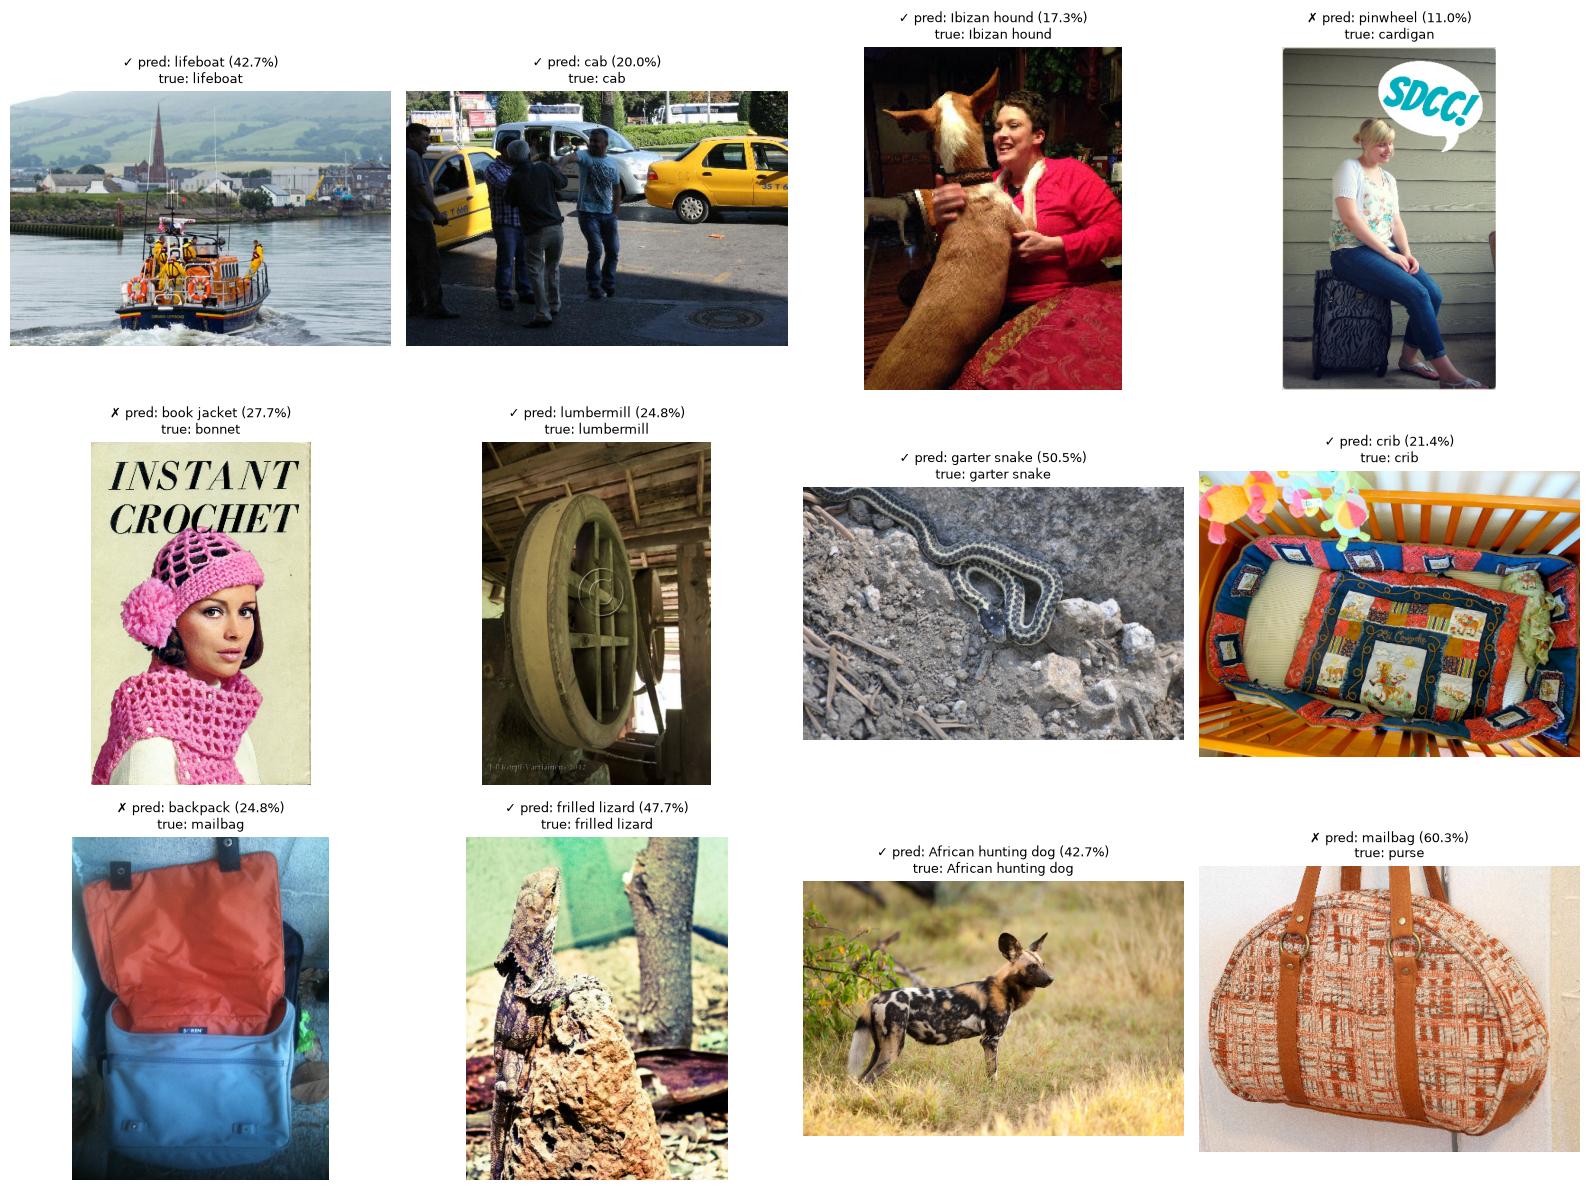

In [22]:
display(predictions.head(10))

sample_count = min(NUM_EXAMPLES_TO_SHOW, len(predictions))
example_rows = predictions.sample(sample_count, random_state=RANDOM_SEED).reset_index(drop=True)
columns = 4
rows = int(np.ceil(sample_count / columns))
figure, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows))
axes = np.atleast_1d(axes).ravel()
for axis, (_, row) in zip(axes, example_rows.iterrows()):
    with Image.open(DATASET_ROOT / row["image_path"]) as image:
        axis.imshow(image.convert("RGB"))
    mark = "✓" if row["correct_top1"] else "✗"
    axis.set_title(
        f"{mark} pred: {row['predicted_name']} ({row['confidence']:.1%})\ntrue: {row['target_name']}",
        fontsize=9,
    )
    axis.axis("off")
for axis in axes[sample_count:]:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 10. Classify one custom image (optional)

Set `CUSTOM_IMAGE_PATH` in the configuration cell, then rerun this cell.

In [23]:
def classify_image(image_path, current_model=model, top_k=TOP_K):
    image_path = Path(image_path)
    with Image.open(image_path) as image:
        rgb_image = image.convert("RGB")
        tensor = EVAL_TRANSFORM(rgb_image).unsqueeze(0).to(DEVICE)
        current_model.eval()
        with torch.inference_mode(), autocast_context():
            probabilities = torch.softmax(current_model(tensor).float(), dim=1)[0]
        values, indices = probabilities.topk(top_k)
        result = pd.DataFrame({
            "class_idx": indices.cpu().tolist(),
            "class_name": [CLASS_NAMES[index] for index in indices.cpu().tolist()],
            "probability": values.cpu().tolist(),
        })
        plt.figure(figsize=(6, 6))
        plt.imshow(rgb_image)
        plt.title(f"Top prediction: {result.iloc[0]['class_name']} ({result.iloc[0]['probability']:.1%})")
        plt.axis("off")
        plt.show()
    return result

if CUSTOM_IMAGE_PATH is not None:
    display(classify_image(CUSTOM_IMAGE_PATH))
else:
    print("Set CUSTOM_IMAGE_PATH in the configuration cell to classify your own image.")

Set CUSTOM_IMAGE_PATH in the configuration cell to classify your own image.


## 11. Artifact summary

Keep the `data/` and `artifacts/` directories beside this notebook to rerun without re-downloading, retraining, or recomputing predictions.

In [24]:
artifact_rows = []
for path in [
    DATASET_ROOT, ARCHIVE_PATH, MANIFEST_PATH, CLASS_NAMES_PATH, ACTIVE_MODEL_PATH,
    PREDICTIONS_PATH, METRICS_PATH, CACHE_METADATA_PATH,
]:
    exists = path.exists()
    if exists and path.is_file():
        size = path.stat().st_size
    elif exists and path.is_dir():
        size = sum(item.stat().st_size for item in path.rglob("*") if item.is_file())
    else:
        size = 0
    artifact_rows.append({"artifact": str(path), "exists": exists, "size_mb": round(size / 1024**2, 2)})
display(pd.DataFrame(artifact_rows))

,artifact,exists,size_mb
0,/home/abbi/tamug_hdc_uav_v2/data/imagenetv2-ma...,True,1186.97
1,/home/abbi/tamug_hdc_uav_v2/data/imagenetv2-ma...,True,1205.52
2,/home/abbi/tamug_hdc_uav_v2/artifacts/imagenet...,True,0.68
3,/home/abbi/tamug_hdc_uav_v2/artifacts/imagenet...,True,0.01
4,/home/abbi/tamug_hdc_uav_v2/artifacts/resnet50...,True,97.80
5,/home/abbi/tamug_hdc_uav_v2/artifacts/predicti...,True,3.11
6,/home/abbi/tamug_hdc_uav_v2/artifacts/metrics_...,True,0.00
7,/home/abbi/tamug_hdc_uav_v2/artifacts/cache_ma...,True,0.00
